## <div align="center"> TUGAS LAB IS545 DATAWAREHOUSE </div>
### <div align="center"> WEEK 08 : Data Visualization </div>

#### <div align="center"> Semester Genap 2024/2025 </div>

In [73]:
import datetime
import uuid

myName = "Farell Eugene"
myNIM = "88624"

In [75]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(myName))
print("NIM: \t\t{}".format(myNIM))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Farell Eugene
NIM: 		88624
Start: 		2024-11-02 11:22:51.935243
Device ID: 	20025475-98d2-11ef-a7f2-50ebf6d53484



---

### Dataset yang dipakai:

1. [phi_minimart] – sumber : [excel]

---

### Hasil kerja

#### Importing system library

In [79]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Importing numpy library

In [83]:
file_path = r"phi_minimart.xlsx"
df = pd.read_excel(file_path, sheet_name='Sheet1')

In [84]:
df.head()

,sk_produk,sk_cabang,sk_karyawan,date_sk,jumlah_pembelian,harga_berlaku_cabang,modal_cabang,biaya_cabang,total_harga_jual,total_biaya_cabang,total_modal_cabang
0,40,39,15,1,12,15090,14310,220,181080,2640,171720
1,23,39,18,1,16,14170,13400,340,226720,5440,214400
2,20,39,24,1,12,5240,4990,70,62880,840,59880
3,2,39,12,1,11,4220,4040,10,46420,110,44440
4,36,39,9,1,14,30060,28850,570,420840,7980,403900


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55465 entries, 0 to 55464
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   sk_produk             55465 non-null  int64
 1   sk_cabang             55465 non-null  int64
 2   sk_karyawan           55465 non-null  int64
 3   date_sk               55465 non-null  int64
 4   jumlah_pembelian      55465 non-null  int64
 5   harga_berlaku_cabang  55465 non-null  int64
 6   modal_cabang          55465 non-null  int64
 7   biaya_cabang          55465 non-null  int64
 8   total_harga_jual      55465 non-null  int64
 9   total_biaya_cabang    55465 non-null  int64
 10  total_modal_cabang    55465 non-null  int64
dtypes: int64(11)
memory usage: 4.7 MB


In [86]:
df.isnull().sum()

sk_produk               0
sk_cabang               0
sk_karyawan             0
date_sk                 0
jumlah_pembelian        0
harga_berlaku_cabang    0
modal_cabang            0
biaya_cabang            0
total_harga_jual        0
total_biaya_cabang      0
total_modal_cabang      0
dtype: int64

In [87]:
constant_columns = [col for col in df.columns if df[col].nunique() == 1]
print("Constant columns: ", constant_columns)

Constant columns:  ['sk_cabang']


In [88]:
df = df.drop(columns=constant_columns)

In [89]:
df['revenue'] = df['jumlah_pembelian'] * df['harga_berlaku_cabang']

df['gross_profit'] = df['total_harga_jual'] - df['total_biaya_cabang']

df['net_profit'] = df['gross_profit'] - df['total_modal_cabang']

summary = df[['revenue', 'gross_profit', 'net_profit']].sum()

print("Summary Metrics: ")
print(summary)

Summary Metrics: 
revenue         8019711740
gross_profit    7923344000
net_profit       304515050
dtype: int64


In [90]:
df.describe()

,sk_produk,sk_karyawan,date_sk,jumlah_pembelian,harga_berlaku_cabang,modal_cabang,biaya_cabang,total_harga_jual,total_biaya_cabang,total_modal_cabang,revenue,gross_profit,net_profit
count,55465.000000,55465.000000,55465.000000,55465.000000,55465.000000,55465.000000,55465.000000,5.546500e+04,55465.000000,5.546500e+04,5.546500e+04,5.546500e+04,55465.000000
mean,20.993041,13.749049,69.806220,10.493879,13793.153160,13103.545299,165.655639,1.445905e+05,1737.451366,1.373628e+05,1.445905e+05,1.428530e+05,5490.219959
std,11.817253,8.331915,39.999723,5.760644,18823.765796,17883.645916,276.371127,2.384429e+05,3454.075857,2.265281e+05,2.384429e+05,2.356374e+05,9405.875213
min,1.000000,1.000000,1.000000,1.000000,880.000000,840.000000,0.000000,8.900000e+02,0.000000,8.400000e+02,8.900000e+02,8.700000e+02,10.000000
25%,11.000000,6.000000,35.000000,6.000000,5000.000000,4740.000000,30.000000,2.836000e+04,200.000000,2.696000e+04,2.836000e+04,2.800000e+04,1020.000000
50%,21.000000,15.000000,70.000000,10.000000,8050.000000,7640.000000,90.000000,7.536000e+04,700.000000,7.164000e+04,7.536000e+04,7.440000e+04,2730.000000
75%,31.000000,21.000000,104.000000,15.000000,14370.000000,13650.000000,180.000000,1.545500e+05,1800.000000,1.468600e+05,1.545500e+05,1.526200e+05,5760.000000
max,41.000000,27.000000,139.000000,20.000000,100980.000000,96290.000000,2410.000000,2.015600e+06,45410.000000,1.925800e+06,2.015600e+06,2.011600e+06,108000.000000


### REVENUE DISTRIBUTION

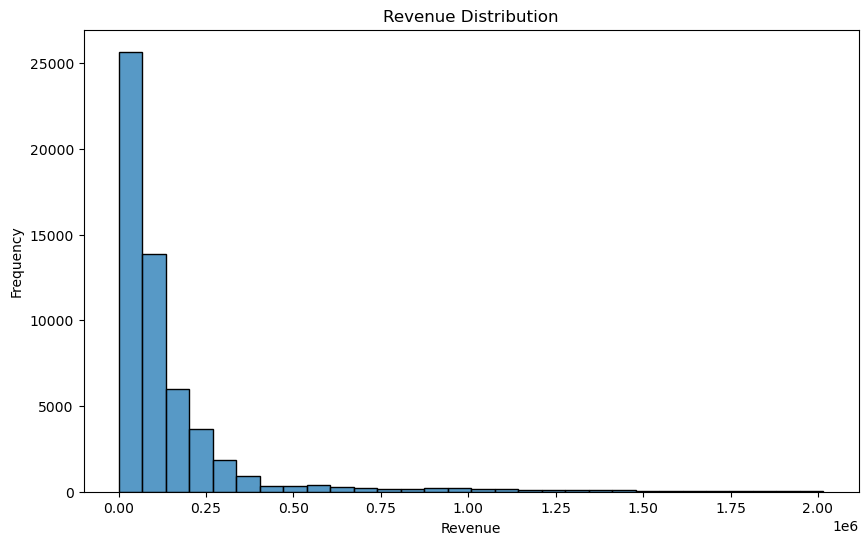

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['revenue'], bins=30)
plt.title('Revenue Distribution')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.show()


### REVENUE AND COSTS OVER TIME

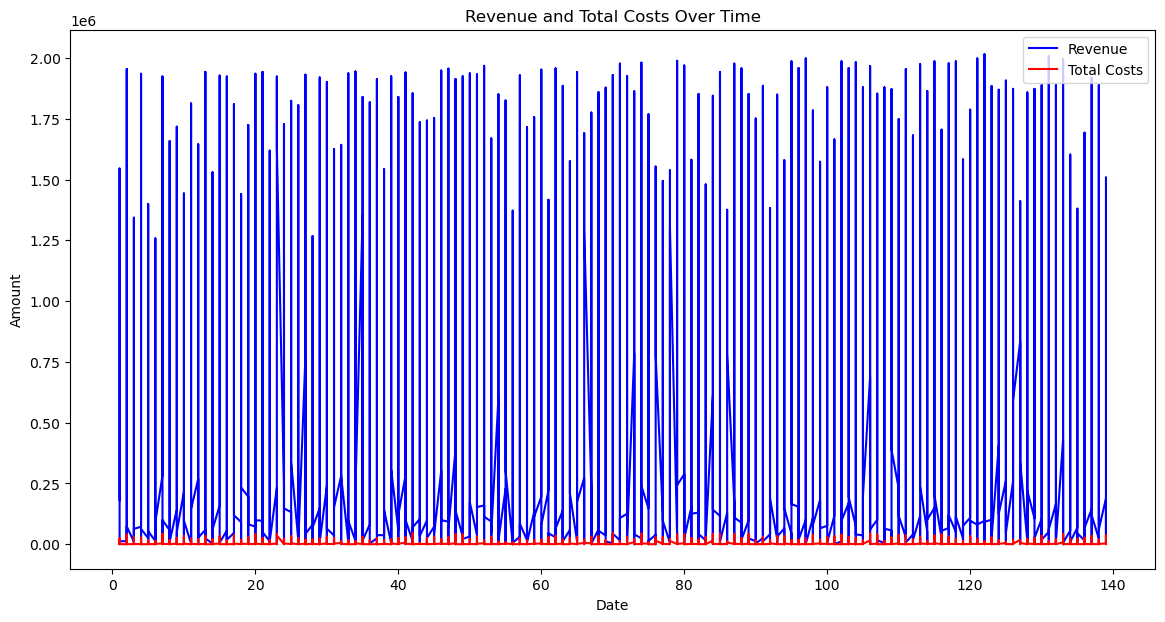

In [94]:
plt.figure(figsize=(14, 7))
plt.plot(df['date_sk'], df['revenue'], label='Revenue', color='blue')
plt.plot(df['date_sk'], df['total_biaya_cabang'], label='Total Costs', color='red')
plt.title('Revenue and Total Costs Over Time')
plt.xlabel('Date')
plt.ylabel('Amount')
plt.legend()
plt.show()


### SCATTER PLOT OF PURCHASES VS TOTAL SALES

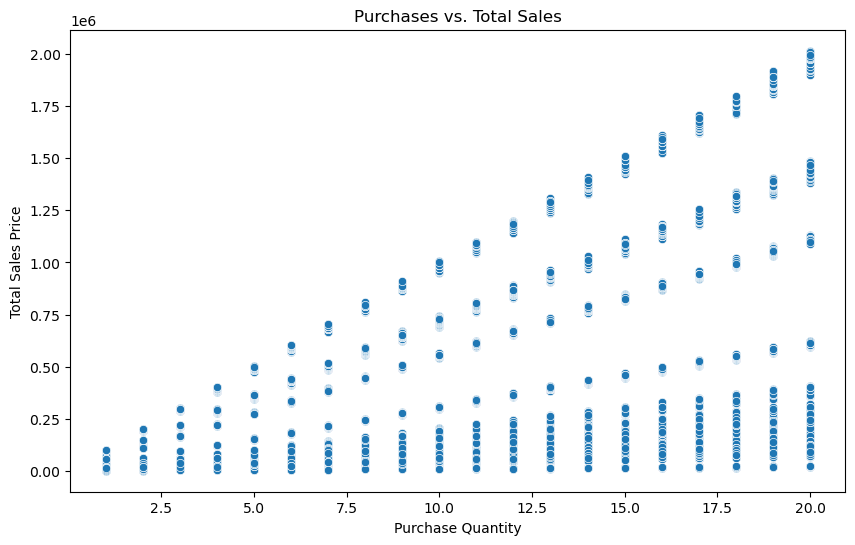

In [96]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['jumlah_pembelian'], y=df['total_harga_jual'])
plt.title('Purchases vs. Total Sales')
plt.xlabel('Purchase Quantity')
plt.ylabel('Total Sales Price')
plt.show()


### CORRELATION HEATMAP

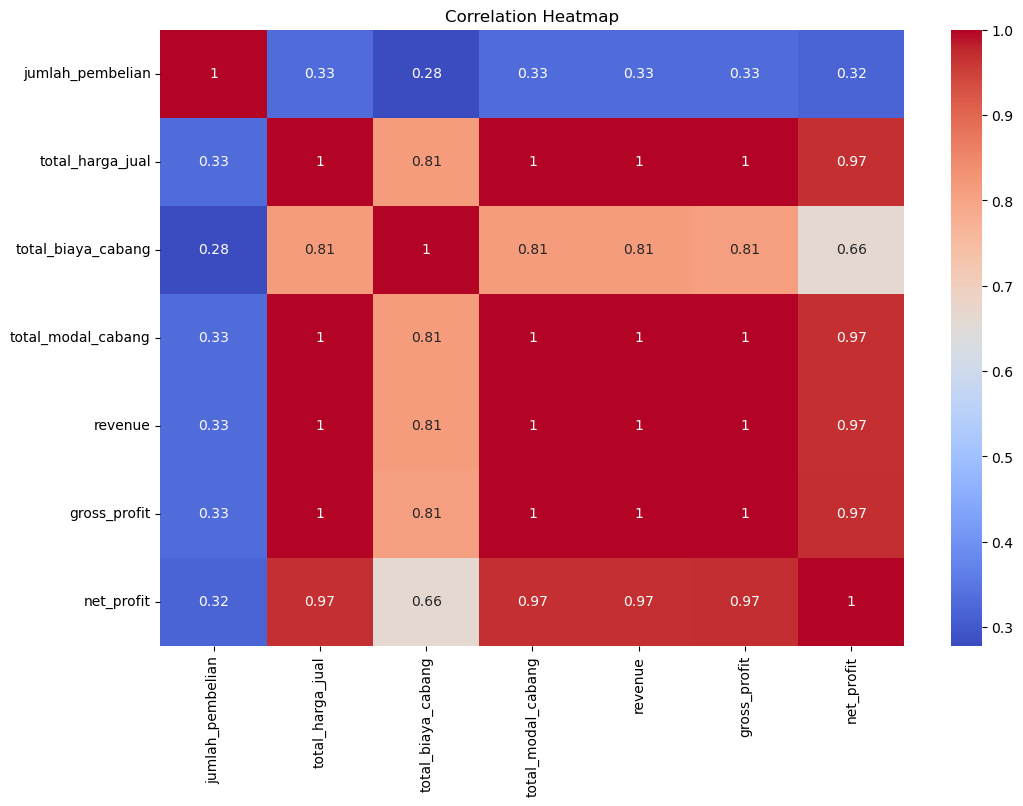

In [98]:
corr_matrix = df[['jumlah_pembelian', 'total_harga_jual', 'total_biaya_cabang', 'total_modal_cabang', 'revenue', 'gross_profit', 'net_profit']].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


---

### Kesimpulan

Dengan adanya visualisasi, kita dapat menganalisa suatu data yang dapat dijadikan pertimbangan untuk mengambil keputusan

---

In [68]:
# Footer
myDate = datetime.datetime.now()
print("I certify that this is my own work.")
print("Signed by:")
print("Name: Farell Eugene\t\t{}".format(myName))
print("NIM:\t\t{}".format(myNIM))
print("Time-stamp:\t{}".format(myDate))

I certify that this is my own work.
Signed by:
Name: Farell Eugene		Farell Eugene
NIM:		88624
Time-stamp:	2024-11-02 11:15:01.287946


***

### Save the notebook, then convert the notebook to html (by running the next code).

In [111]:
!jupyter nbconvert --to html "./DWH WEEK 8.ipynb" --output-dir="./"

[NbConvertApp] Converting notebook ./DWH WEEK 8.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 582814 bytes to DWH WEEK 8.html
